# Breast Cancer Classification Challenge

## Breast Cancer Wisconsin Diagnostic dataset

This notebook develops a complete, reproducible supervised-learning workflow for classifying breast-tumor observations as **malignant** or **benign**. The revised visual narrative moves from data quality and class balance to model selection, held-out performance, calibration, and interpretation.

> **Educational scope:** the model and graphics support data-science learning. They do not constitute a medical diagnosis or clinical recommendation.

## Objectives and evaluation design

The positive class is **malignant** because sensitivity to malignant observations is important to the interpretation of errors. The workflow follows four controls:

1. A fixed stratified test set is created before modeling.
2. Learned preprocessing is contained inside sklearn pipelines.
3. Candidate models are compared with stratified cross-validation using training data only.
4. The test set is evaluated once after model selection and tuning.

ROC AUC is the model-selection measure. The final report also includes sensitivity, specificity, precision, F1, average precision, calibration, and a confusion matrix.

python -m pip install -r requirements.txt

conda env update -f environment.yml –prune

pip install joblib matplotlib numpy pandas seaborn 

pip install scikit-learn


In [4]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
)

# The notebook works whether VS Code starts in the project root or notebooks folder.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").exists():
    raise FileNotFoundError("Open this notebook from the Challenge_Cancer_Detection project folder.")

sys.path.insert(0, str(PROJECT_ROOT))

from src.cancer_detection import (
    build_models,
    calibration_points,
    compare_models,
    compute_permutation_importance,
    evaluate_model,
    load_dataset,
    save_json,
    save_model,
    split_dataset,
    tune_model,
    validate_dataset,
)

RAW_DATA = PROJECT_ROOT / "data/raw/breast_cancer_wisconsin.csv"
PROCESSED_DIR = PROJECT_ROOT / "data/processed"
MODEL_PATH = PROJECT_ROOT / "models/best_model.joblib"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

for directory in [RAW_DATA.parent, PROCESSED_DIR, MODEL_PATH.parent, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Consistent, color-blind-friendly visual language used throughout the notebook.
COLORS = {
    "navy": "#153B5B",
    "blue": "#2F80ED",
    "teal": "#18A999",
    "red": "#D64550",
    "gold": "#F2B134",
    "gray": "#6B7280",
    "light": "#EEF3F8",
}
CLASS_COLORS = {"Benign": COLORS["blue"], "Malignant": COLORS["red"]}

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 12)

def save_figure(fig, filename: str) -> None:
    """Save every figure with consistent quality and spacing."""
    fig.savefig(FIGURES_DIR / filename, dpi=200, bbox_inches="tight", facecolor="white")

print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\osval\OneDrive\Documents\3. Projectos Visual Studio\CancerDetection


## Stage 1 Data acquisition

The dataset is loaded from `scikit-learn`, which distributes a copy of the Wisconsin Diagnostic Breast Cancer data. The original target encoding is 0 for malignant and 1 for benign. The project deliberately converts it to **1 for malignant** so every positive-class measure has the same clinical interpretation.

An auditable CSV snapshot is written to `data/raw`. It is excluded from Git because the notebook can regenerate it.


In [5]:
X, y, dataset_metadata = load_dataset(save_path=RAW_DATA)
print(json.dumps(dataset_metadata, indent=2))
print(f"Raw snapshot: {RAW_DATA}")
print(X.head())


{
  "source": "scikit-learn load_breast_cancer",
  "dataset": "Breast Cancer Wisconsin Diagnostic",
  "rows": 569,
  "features": 30,
  "positive_class": "malignant",
  "target_mapping": {
    "benign": 0,
    "malignant": 1
  }
}
Raw snapshot: C:\Users\osval\OneDrive\Documents\3. Projectos Visual Studio\CancerDetection\data\raw\breast_cancer_wisconsin.csv
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  ...  worst smoothness  worst compactness  \
0           0.27760  ...            0.1622             0.6656   
1           0.07864  ...            0.1238             

## Data dictionary

Each predictor is a continuous numeric measurement derived from a digitized image of a fine needle aspirate of a breast mass. The prefixes `mean`, `error`, and `worst` describe the aggregation used for each cell-nucleus characteristic. The target is separate from the predictors and contains 1 for malignant and 0 for benign.


In [6]:
data_dictionary = pd.DataFrame({
    "attribute": list(X.columns) + [y.name],
    "type": ["numeric continuous"] * X.shape[1] + ["binary target"],
    "domain": ["finite real value"] * X.shape[1] + ["0 benign, 1 malignant"],
    "modeling_role": ["predictor"] * X.shape[1] + ["target"],
})
print(data_dictionary.to_string(index=False))


              attribute               type                domain modeling_role
            mean radius numeric continuous     finite real value     predictor
           mean texture numeric continuous     finite real value     predictor
         mean perimeter numeric continuous     finite real value     predictor
              mean area numeric continuous     finite real value     predictor
        mean smoothness numeric continuous     finite real value     predictor
       mean compactness numeric continuous     finite real value     predictor
         mean concavity numeric continuous     finite real value     predictor
    mean concave points numeric continuous     finite real value     predictor
          mean symmetry numeric continuous     finite real value     predictor
 mean fractal dimension numeric continuous     finite real value     predictor
           radius error numeric continuous     finite real value     predictor
          texture error numeric continuous     finit

## Stage 2 — Data validation and exploratory analysis

The quality check tests row alignment, duplicate column names, numeric predictors, finite values, missing values, duplicate records, and target labels. The visual exploration then answers three questions:

1. Is the target substantially imbalanced?
2. Which measurements have the strongest univariate association with malignancy?
3. How redundant are the strongest measurements with one another?

In [7]:
quality_report = validate_dataset(X, y)
print(json.dumps(quality_report, indent=2))

summary = X.describe().T
summary["missing"] = X.isna().sum()
print(summary.head(10).round(3).to_string())


{
  "rows": 569,
  "features": 30,
  "missing_values": 0,
  "duplicate_rows": 0,
  "infinite_values": 0,
  "class_counts": {
    "0": 357,
    "1": 212
  }
}
                        count     mean      std      min      25%      50%      75%       max  missing
mean radius             569.0   14.127    3.524    6.981   11.700   13.370   15.780    28.110        0
mean texture            569.0   19.290    4.301    9.710   16.170   18.840   21.800    39.280        0
mean perimeter          569.0   91.969   24.299   43.790   75.170   86.240  104.100   188.500        0
mean area               569.0  654.889  351.914  143.500  420.300  551.100  782.700  2501.000        0
mean smoothness         569.0    0.096    0.014    0.053    0.086    0.096    0.105     0.163        0
mean compactness        569.0    0.104    0.053    0.019    0.065    0.093    0.130     0.345        0
mean concavity          569.0    0.089    0.080    0.000    0.030    0.062    0.131     0.427        0
mean concave point

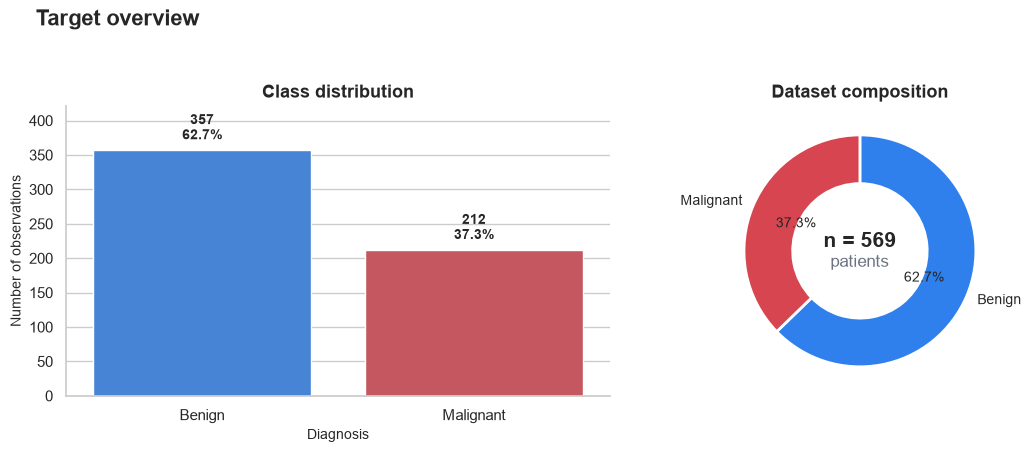

In [8]:
class_labels = y.map({0: "Benign", 1: "Malignant"})
class_counts = class_labels.value_counts().reindex(["Benign", "Malignant"])
class_percentages = class_counts / class_counts.sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.35, 1]})

# Count view
sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette=CLASS_COLORS,
    legend=False,
    ax=axes[0],
)
axes[0].set(title="Class distribution", xlabel="Diagnosis", ylabel="Number of observations")
axes[0].set_ylim(0, class_counts.max() * 1.18)
for bar, count, share in zip(axes[0].patches, class_counts.values, class_percentages.values):
    axes[0].annotate(
        f"{count:,}\n{share:.1%}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center", va="bottom", xytext=(0, 5), textcoords="offset points",
        fontsize=10, fontweight="bold",
    )

# Composition view
axes[1].pie(
    class_counts.values,
    labels=class_counts.index,
    colors=[CLASS_COLORS[label] for label in class_counts.index],
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 10},
)
axes[1].text(0, 0.08, f"n = {len(y):,}", ha="center", va="center", fontsize=15, fontweight="bold")
axes[1].text(0, -0.10, "patients", ha="center", va="center", color=COLORS["gray"])
axes[1].set_title("Dataset composition")

fig.suptitle("Target overview", fontsize=16, fontweight="bold", x=0.04, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_figure(fig, "class_distribution.png")
plt.show()

The feature scales differ substantially, so distance-based and linear margin models require scaling. Scaling will occur inside each pipeline and will be learned independently within each validation fold. Correlations below are descriptive and are not used to select features before splitting.


worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
mean concavity          0.696
worst concavity         0.660


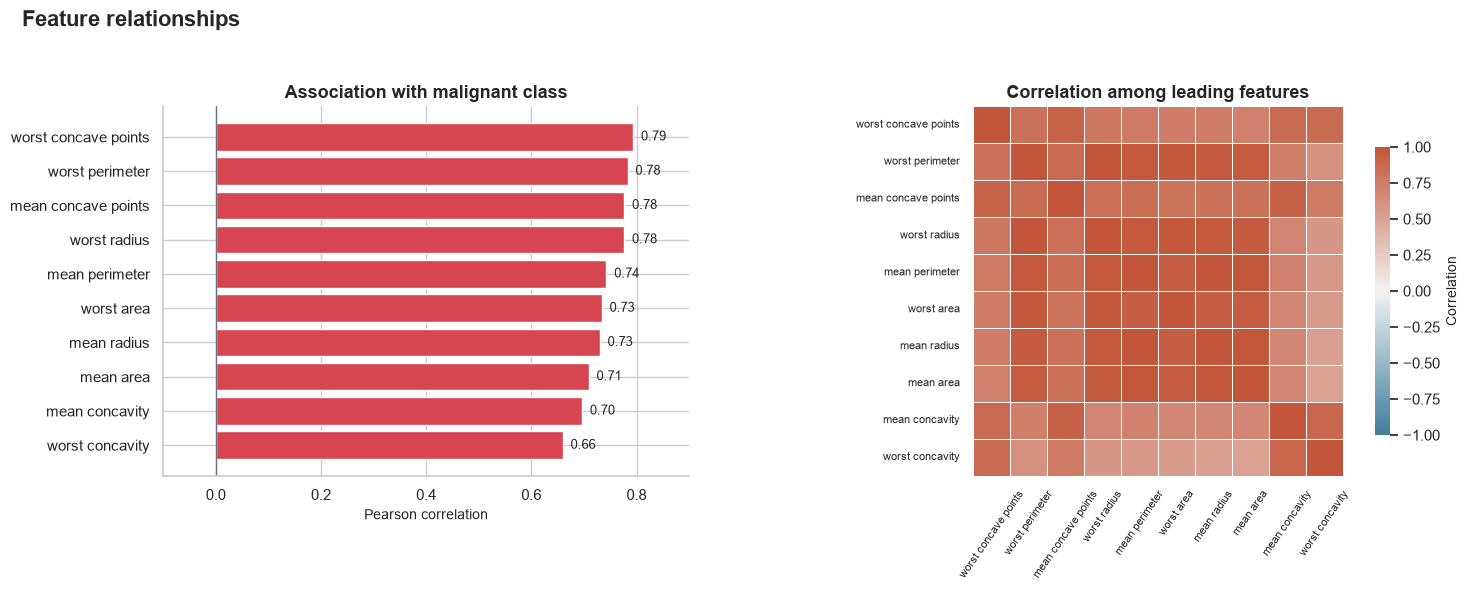

In [9]:
correlations = X.assign(malignant=y).corr(numeric_only=True)["malignant"].drop("malignant")
correlations = correlations.reindex(correlations.abs().sort_values(ascending=False).index)
top_features = correlations.head(10).index.tolist()
print(correlations.head(10).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.25]})

# Signed association with the positive class
top_correlations = correlations.head(10).sort_values()
bar_colors = [COLORS["red"] if value > 0 else COLORS["blue"] for value in top_correlations]
axes[0].barh(top_correlations.index, top_correlations.values, color=bar_colors)
axes[0].axvline(0, color=COLORS["gray"], linewidth=1)
axes[0].set(title="Association with malignant class", xlabel="Pearson correlation", ylabel="")
axes[0].set_xlim(min(-0.1, top_correlations.min() - 0.05), 0.9)
for y_pos, value in enumerate(top_correlations.values):
    axes[0].text(value + 0.015, y_pos, f"{value:.2f}", va="center", fontsize=9)

# Redundancy among the same leading features
corr_matrix = X[top_features].corr()
sns.heatmap(
    corr_matrix,
    cmap=sns.diverging_palette(230, 20, as_cmap=True),
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlation", "shrink": 0.78},
    ax=axes[1],
)
axes[1].set_title("Correlation among leading features")
axes[1].tick_params(axis="x", rotation=55, labelsize=8)
axes[1].tick_params(axis="y", rotation=0, labelsize=8)

fig.suptitle("Feature relationships", fontsize=16, fontweight="bold", x=0.02, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_figure(fig, "feature_relationships.png")
plt.show()

## Train and test partitions

The 80/20 split is stratified so both partitions preserve approximately the same malignant proportion. The indices and random seed are fixed for reproducibility. Processed copies are saved only to make the experiment easier to audit; they remain regenerable artifacts.


partition  rows  malignant_count  malignant_rate
 Training   455              170        0.373626
     Test   114               42        0.368421


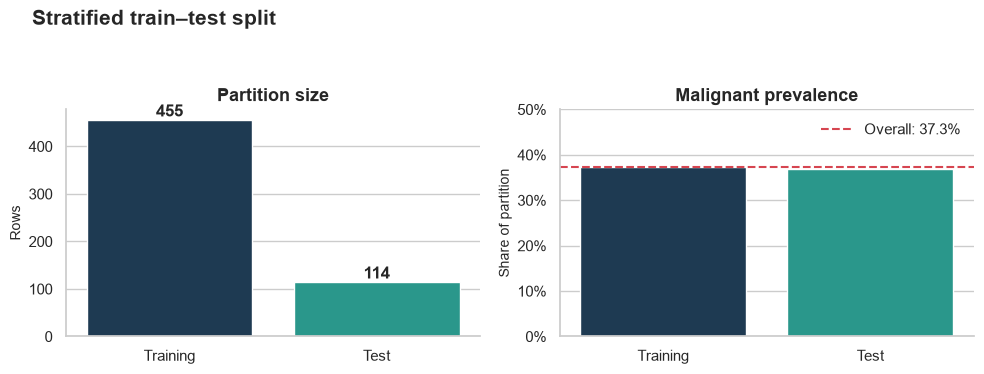

In [10]:
X_train, X_test, y_train, y_test = split_dataset(X, y, test_size=0.20)

train_data = X_train.assign(malignant=y_train)
test_data = X_test.assign(malignant=y_test)
train_data.to_csv(PROCESSED_DIR / "train.csv", index=True, index_label="source_index")
test_data.to_csv(PROCESSED_DIR / "test.csv", index=True, index_label="source_index")

split_summary = pd.DataFrame({
    "partition": ["Training", "Test"],
    "rows": [len(y_train), len(y_test)],
    "malignant_count": [int(y_train.sum()), int(y_test.sum())],
    "malignant_rate": [float(y_train.mean()), float(y_test.mean())],
})
print(split_summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
sns.barplot(data=split_summary, x="partition", y="rows", hue="partition",
            palette=[COLORS["navy"], COLORS["teal"]], legend=False, ax=axes[0])
axes[0].set(title="Partition size", xlabel="", ylabel="Rows")
for bar, value in zip(axes[0].patches, split_summary["rows"]):
    axes[0].text(bar.get_x() + bar.get_width()/2, value + 8, f"{value:,}", ha="center", fontweight="bold")

sns.barplot(data=split_summary, x="partition", y="malignant_rate", hue="partition",
            palette=[COLORS["navy"], COLORS["teal"]], legend=False, ax=axes[1])
axes[1].axhline(y.mean(), color=COLORS["red"], linestyle="--", linewidth=1.5,
                label=f"Overall: {y.mean():.1%}")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set(title="Malignant prevalence", xlabel="", ylabel="Share of partition", ylim=(0, 0.5))
axes[1].legend(loc="upper right")

fig.suptitle("Stratified train–test split", fontsize=15, fontweight="bold", x=0.04, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.92))
save_figure(fig, "train_test_split.png")
plt.show()

## Stage 3 Baseline and candidate models

The dummy classifier establishes the minimum reference. Six candidate classifiers represent linear, margin-based, neighborhood, tree, ensemble, and boosting approaches. Pipelines prevent leakage by fitting `StandardScaler` only on the training portion of each fold when scaling is needed.


In [11]:
models = build_models()
for name, model in models.items():
    print(f"{name}: {model}")


Dummy most frequent: DummyClassifier(strategy='most_frequent')
Logistic regression: Pipeline(steps=[('scale', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=5000,
                                    random_state=42))])
Support vector machine: Pipeline(steps=[('scale', StandardScaler()),
                ('model',
                 SVC(class_weight='balanced', probability=True,
                     random_state=42))])
K nearest neighbors: Pipeline(steps=[('scale', StandardScaler()),
                ('model', KNeighborsClassifier(n_neighbors=7))])
Decision tree: DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42)
Random forest: RandomForestClassifier(class_weight='balanced', n_estimators=400, n_jobs=1,
                       random_state=42)
Gradient boosting: GradientBoostingClassifier(random_state=42)


## Stage 4 Cross-validated comparison

Five-fold stratified cross-validation estimates performance variation on the training set. The table is sorted by mean ROC AUC. The held-out test set does not participate in this comparison.


In [12]:
comparison = compare_models(models, X_train, y_train, folds=5)
comparison.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)

columns_to_show = [
    "model", "mean_roc_auc", "std_roc_auc", "mean_average_precision",
    "mean_recall", "mean_precision", "mean_f1"
]
display(comparison[columns_to_show].round(4).style
        .background_gradient(subset=["mean_roc_auc", "mean_average_precision", "mean_recall", "mean_precision", "mean_f1"], cmap="Blues")
        .format(precision=4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.05, 1.25]})

# Primary selection metric with fold-to-fold variability
ordered = comparison.sort_values("mean_roc_auc")
colors = [COLORS["gray"] if name == "Dummy most frequent" else COLORS["navy"] for name in ordered["model"]]
axes[0].barh(
    ordered["model"], ordered["mean_roc_auc"],
    xerr=ordered["std_roc_auc"], color=colors, capsize=3, alpha=0.95,
)
axes[0].axvline(0.5, color=COLORS["red"], linestyle="--", linewidth=1.3, label="Random ranking")
axes[0].set(title="Primary metric: ROC AUC", xlabel="Mean five-fold ROC AUC", ylabel="", xlim=(0.45, 1.01))
axes[0].legend(loc="lower right")

# Multimetric view makes trade-offs visible instead of ranking by one number only.
metric_columns = ["mean_roc_auc", "mean_average_precision", "mean_recall", "mean_precision", "mean_f1"]
metric_labels = ["ROC AUC", "Avg. precision", "Recall", "Precision", "F1"]
heatmap_data = comparison.set_index("model")[metric_columns].rename(columns=dict(zip(metric_columns, metric_labels)))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.6,
    cbar_kws={"label": "Score", "shrink": 0.75},
    ax=axes[1],
)
axes[1].set(title="Cross-validation performance profile", xlabel="Metric", ylabel="")
axes[1].tick_params(axis="x", rotation=35)
axes[1].tick_params(axis="y", rotation=0)

fig.suptitle("Candidate model comparison", fontsize=16, fontweight="bold", x=0.02, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_figure(fig, "model_comparison.png")
plt.show()

c:\Users\osval\.conda\envs\CancerDetection\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\osval\.conda\envs\CancerDetection\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\osval\.conda\envs\CancerDetection\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\osval\.conda\envs\CancerDetection\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` p

AttributeError: The '.style' accessor requires jinja2

## Hyperparameter tuning on training data

The best non-dummy candidate is selected from cross-validation and tuned with a compact model-specific grid. The search again uses only the training partition. Its best estimator is then frozen for the final test.


In [ ]:
candidate_rows = comparison[comparison["model"] != "Dummy most frequent"]
selected_name = str(candidate_rows.iloc[0]["model"])
search = tune_model(selected_name, models[selected_name], X_train, y_train, folds=5)
best_model = search.best_estimator_

print(f"Selected family: {selected_name}")
print(f"Best cross-validated ROC AUC: {search.best_score_:.4f}")
print(f"Best parameters: {search.best_params_}")


## Stage 5 — Final evaluation on held-out data

The decision threshold remains at the model default of 0.5. The dashboard below separates four complementary views:

- **Metric profile:** discrimination and classification scores.
- **Confusion matrices:** raw clinical-style counts and row-normalized error rates.
- **ROC curve:** sensitivity versus false-positive rate across thresholds.
- **Precision–recall curve:** positive-class performance when class prevalence matters.

Here, malignant is class 1; consequently, a false negative is a malignant observation predicted as benign.

In [ ]:
test_metrics, y_pred, y_probability = evaluate_model(best_model, X_test, y_test)
print(json.dumps(test_metrics, indent=2))

metric_map = {
    "Accuracy": test_metrics["accuracy"],
    "Sensitivity": test_metrics["sensitivity_recall"],
    "Specificity": test_metrics["specificity"],
    "Precision": test_metrics["precision"],
    "F1": test_metrics["f1"],
    "ROC AUC": test_metrics["roc_auc"],
    "Avg. precision": test_metrics["average_precision"],
}
metric_frame = pd.DataFrame({"Metric": metric_map.keys(), "Score": metric_map.values()}).sort_values("Score")

fig, ax = plt.subplots(figsize=(9, 4.8))
bar_colors = [COLORS["teal"] if value >= 0.95 else COLORS["gold"] for value in metric_frame["Score"]]
bars = ax.barh(metric_frame["Metric"], metric_frame["Score"], color=bar_colors)
ax.set(title=f"Held-out metric profile — {selected_name}", xlabel="Score", ylabel="", xlim=(0, 1.08))
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.axvline(0.90, color=COLORS["gray"], linestyle=":", linewidth=1)
for bar, value in zip(bars, metric_frame["Score"]):
    ax.text(value + 0.012, bar.get_y() + bar.get_height()/2, f"{value:.1%}", va="center", fontweight="bold")
fig.tight_layout()
save_figure(fig, "test_metric_profile.png")
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Benign", "Malignant"],
    cmap="Blues", colorbar=False, values_format="d", ax=axes[0, 0],
)
axes[0, 0].set_title("Confusion matrix — counts")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Benign", "Malignant"], normalize="true",
    cmap="Blues", colorbar=False, values_format=".1%", ax=axes[0, 1],
)
axes[0, 1].set_title("Confusion matrix — row normalized")

RocCurveDisplay.from_predictions(
    y_test, y_probability, name=f"{selected_name} (AUC={test_metrics['roc_auc']:.3f})", ax=axes[1, 0]
)
axes[1, 0].plot([0, 1], [0, 1], "--", color=COLORS["gray"], label="Random ranking")
axes[1, 0].set_title("ROC curve")
axes[1, 0].legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(
    y_test, y_probability,
    name=f"{selected_name} (AP={test_metrics['average_precision']:.3f})",
    ax=axes[1, 1],
)
axes[1, 1].axhline(y_test.mean(), color=COLORS["gray"], linestyle="--", label=f"Prevalence={y_test.mean():.1%}")
axes[1, 1].set_title("Precision–recall curve")
axes[1, 1].legend(loc="lower left")

fig.suptitle("Held-out evaluation dashboard", fontsize=17, fontweight="bold", x=0.02, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_figure(fig, "final_evaluation.png")
plt.show()

In [ ]:
observed_probability, predicted_probability = calibration_points(y_test, y_probability)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})

axes[0].plot(predicted_probability, observed_probability, marker="o", linewidth=2,
             color=COLORS["navy"], label=selected_name)
axes[0].plot([0, 1], [0, 1], "--", color=COLORS["gray"], label="Perfect calibration")
axes[0].fill_between([0, 1], [0, 1], alpha=0.05, color=COLORS["gray"])
axes[0].set(
    title=f"Reliability curve (Brier={test_metrics['brier_score']:.3f})",
    xlabel="Mean predicted probability",
    ylabel="Observed malignant rate",
    xlim=(0, 1), ylim=(0, 1),
)
axes[0].legend(loc="upper left")

probability_frame = pd.DataFrame({
    "Malignant probability": y_probability,
    "Observed class": y_test.map({0: "Benign", 1: "Malignant"}).values,
})
sns.histplot(
    data=probability_frame,
    x="Malignant probability",
    hue="Observed class",
    hue_order=["Benign", "Malignant"],
    palette=CLASS_COLORS,
    bins=np.linspace(0, 1, 21),
    element="step",
    alpha=0.35,
    common_norm=False,
    ax=axes[1],
)
axes[1].axvline(0.5, color=COLORS["gray"], linestyle="--", linewidth=1.5, label="Threshold = 0.5")
axes[1].set(title="Probability separation by observed class", xlabel="Predicted malignant probability", ylabel="Observations", xlim=(0, 1))

fig.suptitle("Probability quality and separation", fontsize=16, fontweight="bold", x=0.02, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_figure(fig, "calibration_and_probability_distribution.png")
plt.show()

## Stage 6 Model interpretation

Permutation importance measures the decrease in test ROC AUC after shuffling one feature at a time. It is model-agnostic, but importance is not causality. Correlated features can share or mask importance, and the test sample is small.


In [ ]:
importance = compute_permutation_importance(best_model, X_test, y_test)
display(importance.head(15).round(4).style
        .background_gradient(subset=["importance_mean"], cmap="Blues")
        .format({"importance_mean": "{:.4f}", "importance_std": "{:.4f}"}))

top_importance = importance.head(12).sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(9, 6.2))
y_positions = np.arange(len(top_importance))
ax.hlines(y_positions, 0, top_importance["importance_mean"], color=COLORS["light"], linewidth=5)
ax.errorbar(
    top_importance["importance_mean"], y_positions,
    xerr=top_importance["importance_std"],
    fmt="o", markersize=7, color=COLORS["navy"], ecolor=COLORS["gray"], capsize=3,
)
ax.axvline(0, color=COLORS["gray"], linewidth=1)
ax.set_yticks(y_positions, labels=top_importance["feature"])
ax.set(title="Permutation importance on held-out data", xlabel="Decrease in ROC AUC after permutation", ylabel="")
ax.text(
    0.99, 0.02,
    "Larger decrease = greater predictive contribution",
    transform=ax.transAxes, ha="right", va="bottom", color=COLORS["gray"], fontsize=9,
)
fig.tight_layout()
save_figure(fig, "permutation_importance.png")
plt.show()

## Save the reproducible artifacts

The serialized object contains the complete fitted pipeline, including preprocessing. Metadata records the selected model, target meaning, split seed, best parameters, and final metrics. This makes later inference less ambiguous.


In [ ]:
artifact_metadata = {
    **dataset_metadata,
    "selected_model": selected_name,
    "selection_metric": "five-fold cross-validated ROC AUC on training data",
    "best_cv_roc_auc": float(search.best_score_),
    "best_parameters": search.best_params_,
    "random_state": 42,
    "test_size": 0.20,
    "test_metrics": test_metrics,
}

save_model(best_model, MODEL_PATH)
save_json(artifact_metadata, REPORTS_DIR / "metrics.json")
print(f"Model saved to: {MODEL_PATH}")
print(f"Metrics saved to: {REPORTS_DIR / 'metrics.json'}")


## Reproducible inference example

The following cell reloads the saved pipeline and predicts one held-out observation. The example demonstrates the software interface only; it is not a clinical recommendation.


In [ ]:
reloaded_model = joblib.load(MODEL_PATH)
example = X_test.iloc[[0]]
example_probability = float(reloaded_model.predict_proba(example)[0, 1])
example_prediction = int(reloaded_model.predict(example)[0])

print({
    "predicted_class": "malignant" if example_prediction == 1 else "benign",
    "malignant_probability": round(example_probability, 4),
    "actual_class": "malignant" if int(y_test.iloc[0]) == 1 else "benign",
})


## Conclusions and limitations

Use the executed values above to build the final interpretation. At minimum:

1. Compare the selected model with the dummy baseline and explain why ROC AUC alone is not sufficient.
2. Report held-out sensitivity, specificity, precision, F1, ROC AUC, and the false-negative count.
3. Interpret the probability-distribution and calibration panels—not only the hard classifications.
4. Identify the leading permutation-importance features while stating that importance is **not causality**.
5. Discuss the small sample size, correlated predictors, single-source dataset, and lack of external validation.
6. State explicitly that the notebook is an educational prototype and not a clinical diagnostic system.

### Suggested decision-focused closing

The most important error in this framing is a **false negative**: a malignant observation classified as benign. Therefore, any future deployment-oriented study should evaluate clinically justified thresholds, calibration, external cohorts, subgroup performance, and prospective validation under specialist oversight.